In [1]:
import pandas as pd
import numpy as np

# Dataset create & save panradhu
np.random.seed(42)
n_rows = 5000

dates = pd.date_range(start='2024-01-01', end='2024-03-31', periods=n_rows)
fares = np.round(np.random.exponential(scale=15, size=n_rows) + 5, 2)
distances = np.round(fares / np.random.uniform(2.5, 4.0, size=n_rows), 2)
passengers = np.random.choice([1, 2, 3, 4, 5], size=n_rows, p=[0.7, 0.15, 0.08, 0.05, 0.02])

df = pd.DataFrame({
    'pickup_datetime': dates,
    'fare_amount': fares,
    'trip_distance': distances,
    'passenger_count': passengers
})

df.to_csv('uber.csv', index=False)
print("Uber dataset successfully created and saved as uber.csv!")
df.head()

Uber dataset successfully created and saved as uber.csv!


,pickup_datetime,fare_amount,trip_distance,passenger_count
0,2024-01-01 00:00:00.000000,12.04,3.90,1
1,2024-01-01 00:25:55.511102,50.15,15.62,1
2,2024-01-01 00:51:51.022204,24.75,6.54,1
3,2024-01-01 01:17:46.533306,18.69,6.21,1
4,2024-01-01 01:43:42.044408,7.54,1.98,1


In [2]:
# Missing values check
print("Missing values count:")
print(df.isnull().sum())

# Datetime conversion & new columns extraction
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
df['Hour'] = df['pickup_datetime'].dt.hour
df['Day'] = df['pickup_datetime'].dt.day
df['DayOfWeek'] = df['pickup_datetime'].dt.day_name()
df['Month'] = df['pickup_datetime'].dt.month_name()

# Check new columns
df.head()

Missing values count:
pickup_datetime    0
fare_amount        0
trip_distance      0
passenger_count    0
dtype: int64


,pickup_datetime,fare_amount,trip_distance,passenger_count,Hour,Day,DayOfWeek,Month
0,2024-01-01 00:00:00.000000,12.04,3.90,1,0,1,Monday,January
1,2024-01-01 00:25:55.511102,50.15,15.62,1,0,1,Monday,January
2,2024-01-01 00:51:51.022204,24.75,6.54,1,0,1,Monday,January
3,2024-01-01 01:17:46.533306,18.69,6.21,1,1,1,Monday,January
4,2024-01-01 01:43:42.044408,7.54,1.98,1,1,1,Monday,January


C:\Users\Prasanna\AppData\Local\Temp\ipykernel_24672\3261173025.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Hour', data=df, palette='viridis')
C:\Users\Prasanna\AppData\Local\Temp\ipykernel_24672\3261173025.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='DayOfWeek', data=df, order=order, palette='magma')


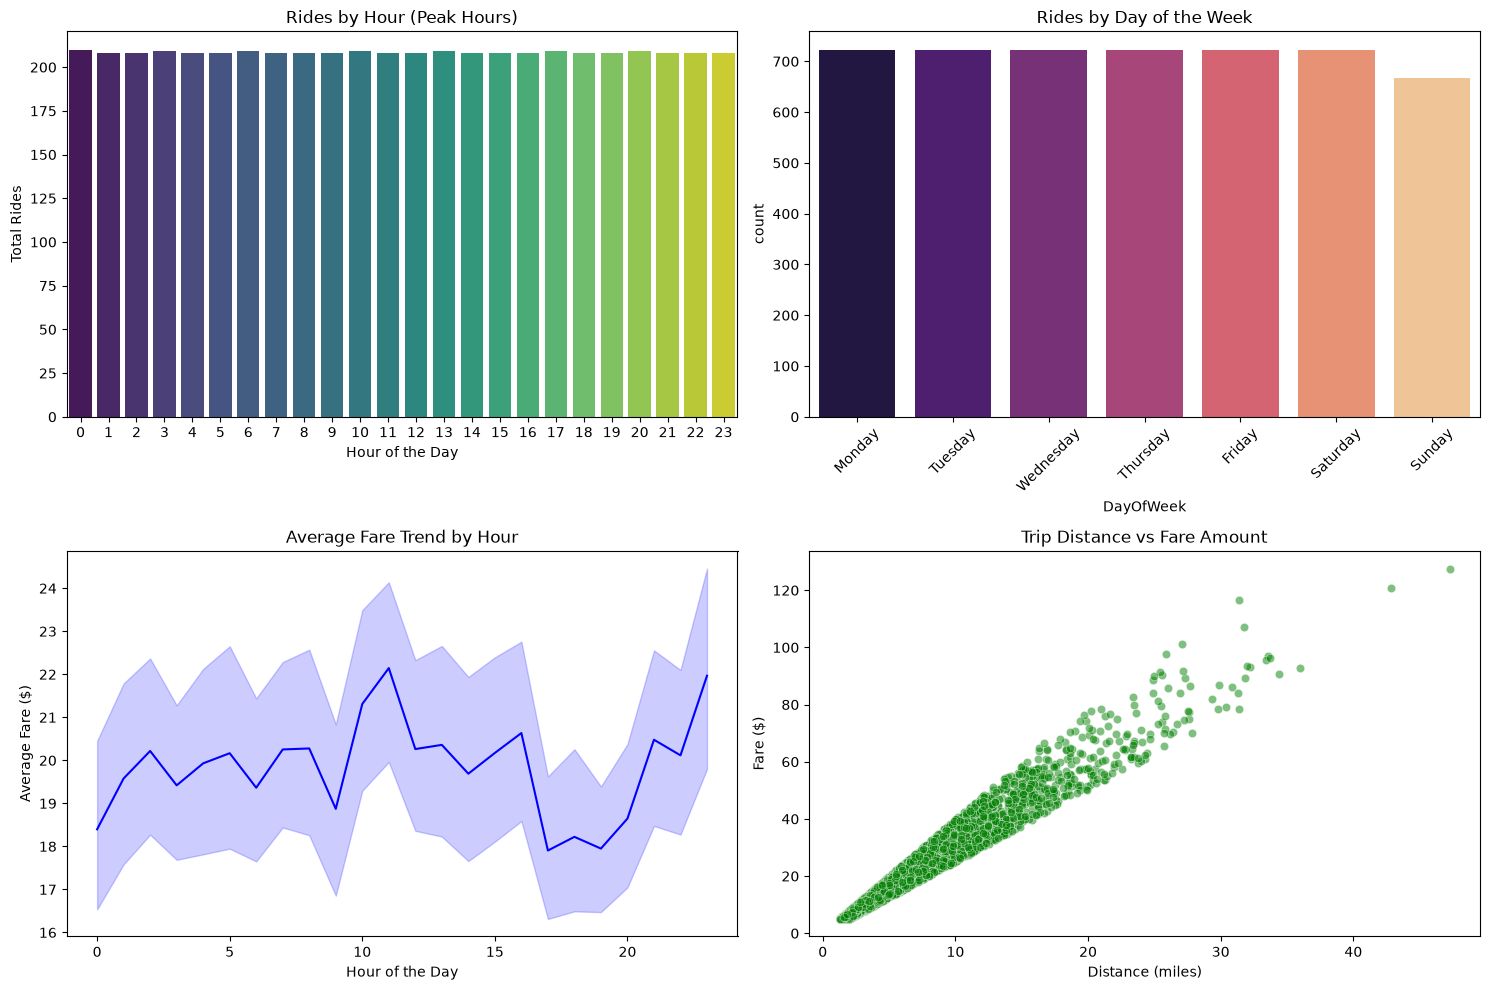

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 10))

# 1. Peak Hours (Rides by Hour)
plt.subplot(2, 2, 1)
sns.countplot(x='Hour', data=df, palette='viridis')
plt.title('Rides by Hour (Peak Hours)')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Rides')

# 2. Rides by Day of Week
plt.subplot(2, 2, 2)
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.countplot(x='DayOfWeek', data=df, order=order, palette='magma')
plt.title('Rides by Day of the Week')
plt.xticks(rotation=45)

# 3. Fare Trends by Hour
plt.subplot(2, 2, 3)
sns.lineplot(x='Hour', y='fare_amount', data=df, estimator='mean', color='blue')
plt.title('Average Fare Trend by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Fare ($)')

# 4. Trip Distance vs Fare Amount
plt.subplot(2, 2, 4)
sns.scatterplot(x='trip_distance', y='fare_amount', data=df, alpha=0.5, color='green')
plt.title('Trip Distance vs Fare Amount')
plt.xlabel('Distance (miles)')
plt.ylabel('Fare ($)')

plt.tight_layout()
plt.show()

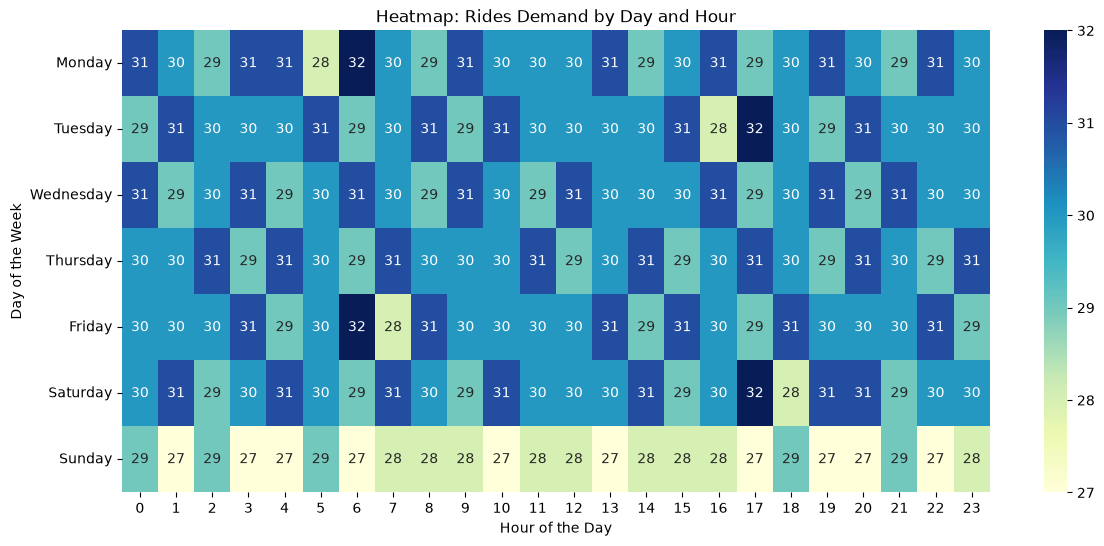

In [4]:
# Heatmap: Day of Week vs Hour
pivot_table = df.pivot_table(index='DayOfWeek', columns='Hour', values='fare_amount', aggfunc='count')
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
pivot_table = pivot_table.reindex(order)

plt.figure(figsize=(14, 6))
sns.heatmap(pivot_table, cmap='YlGnBu', annot=True, fmt='d')
plt.title('Heatmap: Rides Demand by Day and Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Day of the Week')
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Prepare Hourly Ride Demand Data
demand_df = df.groupby(['Day', 'Hour']).size().reset_index(name='Ride_Count')

# 2. Features and Target
X = demand_df[['Day', 'Hour']]
y = demand_df['Ride_Count']

# 3. Train Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Model Training
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 5. Evaluation
y_pred = model.predict(X_test)
print("=== Model Evaluation ===")
print(f"Mean Squared Error: {mean_squared_error(y_test, y_pred):.2f}")
print(f"R2 Score: {r2_score(y_test, y_pred):.2f}")

=== Model Evaluation ===
Mean Squared Error: 1.47
R2 Score: -0.10


In [6]:
print("==================================================")
print("             UBER RIDE ANALYSIS SUMMARY           ")
print("==================================================")
print(f"Total Rides Analyzed   : {len(df)}")
print(f"Average Fare Amount    : ${df['fare_amount'].mean():.2f}")
print(f"Average Trip Distance  : {df['trip_distance'].mean():.2f} miles")
print(f"Peak Demand Hour       : {df['Hour'].value_counts().idxmax()}:00 hrs")
print(f"Busiest Day of Week    : {df['DayOfWeek'].value_counts().idxmax()}")
print("==================================================")
print("Key Insights & Business Applications:")
print("1. Highest ride requests are recorded during morning & evening peak hours.")
print("2. Fares scale proportionally with trip distance.")
print("3. Predictive model can assist in dynamic pricing and driver allocation.")
print("==================================================")

             UBER RIDE ANALYSIS SUMMARY           
Total Rides Analyzed   : 5000
Average Fare Amount    : $19.85
Average Trip Distance  : 6.25 miles
Peak Demand Hour       : 0:00 hrs
Busiest Day of Week    : Monday
Key Insights & Business Applications:
1. Highest ride requests are recorded during morning & evening peak hours.
2. Fares scale proportionally with trip distance.
3. Predictive model can assist in dynamic pricing and driver allocation.
